In [1]:
#!jupyter nbconvert --to script everyModelDocumentation.ipynb


In [2]:
import torch
from everyModelDocumentation import ResPoseNet
import pandas as pd
import torch.nn as nn
import numpy as np
import torchvision.transforms as transforms
import torch.utils.data as data

In [3]:
%env HSA_OVERRIDE_GFX_VERSION=10.3.0
#torch.backends.cuda.matmul.allow_tf32 = False  # Disable TF32 (can cause instability)


env: HSA_OVERRIDE_GFX_VERSION=10.3.0


In [4]:
df = pd.read_pickle('dataset22462_augmented.pkl')
df = df.dropna()
#convert the columns upper neck_X upper neck_Y  head top_X  head top_Y to int64
df = df.astype({'upper neck_X': 'int64', 'upper neck_Y': 'int64', 'head top_X': 'int64', 'head top_Y': 'int64'})
keypoint_columns = [col for col in df.columns if col != 'image'] #todas as coluunas
keypoints = df[keypoint_columns].values.astype(np.float32)

keypoints = keypoints / 224.0 #normaliza os pontos para 0-1

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class PoseDataset(data.Dataset):
    def __init__(self, df):
        self.df = df
        self.images = df['image'].tolist()
        self.keypoints = keypoints
    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_array = self.images[idx]
        img_tensor = transform(img_array) #converter para pythorch
        kp_tensor = torch.tensor(self.keypoints[idx])
        return img_tensor, kp_tensor

In [5]:
dataset = PoseDataset(df)
val_size = int(0.2 * len(dataset))
train_size = len(dataset) - val_size
_, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

val_loader = data.DataLoader(val_dataset, batch_size=16, shuffle=True)

In [6]:
def PCK(preds, targets, threshold=20/224):
    """
    Computes the accuracy of predicted points based on a radius threshold.

    Args:
    - preds (Tensor): Shape (B, 32), predicted x,y coordinates for 16 points.
    - targets (Tensor): Shape (B, 32), ground truth x,y coordinates.
    - threshold (float): Distance threshold for correctness.

    Returns:
    - accuracy (float): The mean accuracy over all points.
    """
    # Reshape to (B, 16, 2) -> Each row is (x, y) pairs
    preds = preds.view(-1, 16, 2)
    targets = targets.view(-1, 16, 2)

    # Compute Euclidean distance per point
    distances = torch.norm(preds - targets, dim=2)  # (B, 16)

    # Check if within the threshold (boolean mask)
    correct = (distances <= threshold).float()  # (B, 16)

    # Compute average accuracy over all points
    accuracy = correct.mean(dim=0)  # Scalar value
    return accuracy


In [7]:
model = ResPoseNet().to("cuda")
model.load_state_dict(torch.load("posev001255.pth"))

/tmp/ipykernel_8807/507392083.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("posev001255.pth"))


<All keys matched successfully>

In [8]:
model.eval()
val_loss = torch.tensor([0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0]).to("cuda")
with torch.no_grad():
    for images, keypoints in val_loader:
        
        images, keypoints = images.to("cuda"), keypoints.to("cuda")
        outputs = model(images)
        loss = PCK(outputs, keypoints)
        val_loss += loss.to("cuda")

media_loss = torch.div(val_loss,val_size/16) * 100

        


/home/miguel/Desktop/LimbsID-Samsung-Final-Project/.venv/lib/python3.12/site-packages/torch/nn/modules/linear.py:125: UserWarning: Attempting to use hipBLASLt on an unsupported architecture! Overriding blas backend to hipblas (Triggered internally at ../aten/src/ATen/Context.cpp:296.)
  return F.linear(input, self.weight, self.bias)


In [9]:
print(media_loss)


tensor([41.8751, 48.2300, 63.5131, 62.5957, 47.9168, 42.0094, 68.7984, 84.5156,
        84.1754, 71.7521, 31.8058, 46.8158, 68.2524, 67.8765, 46.1490, 31.8461],
       device='cuda:0')


In [10]:
media_loss.to("cpu").numpy()

keypoints = [
    ("r ankle_X", "r ankle_Y"),
    ("r knee_X", "r knee_Y"),
    ("r hip_X", "r hip_Y"),
    ("l hip_X", "l hip_Y"),
    ("l knee_X", "l knee_Y"),
    ("l ankle_X", "l ankle_Y"),
    ("pelvis_X", "pelvis_Y"),
    ("thorax_X", "thorax_Y"),
    ("upper neck_X", "upper neck_Y"),
    ("head top_X", "head top_Y"),
    ("r wrist_X", "r wrist_Y"),
    ("r elbow_X", "r elbow_Y"),
    ("r shoulder_X", "r shoulder_Y"),
    ("l shoulder_X", "l shoulder_Y"),
    ("l elbow_X", "l elbow_Y"),
    ("l wrist_X", "l wrist_Y")
]

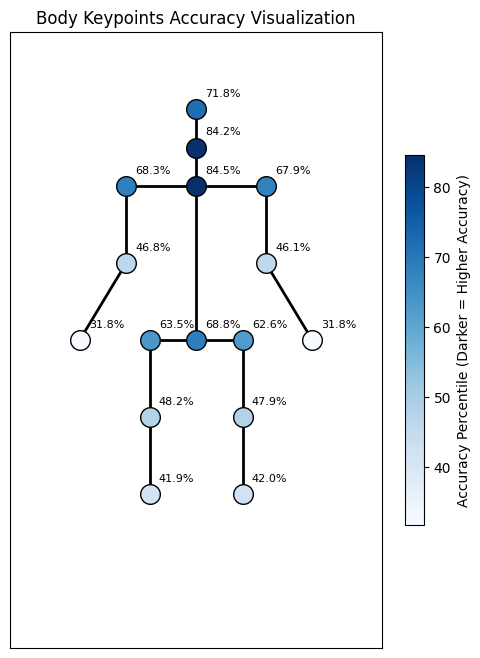

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Define body keypoints
keypoints = [
    ("r ankle", "r ankle"),
    ("r knee", "r knee"),
    ("r hip", "r hip"),
    ("l hip", "l hip"),
    ("l knee", "l knee"),
    ("l ankle", "l ankle"),
    ("pelvis", "pelvis"),
    ("thorax", "thorax"),
    ("upper neck", "upper neck"),
    ("head top", "head top"),
    ("r wrist", "r wrist"),
    ("r elbow", "r elbow"),
    ("r shoulder", "r shoulder"),
    ("l shoulder", "l shoulder"),
    ("l elbow", "l elbow"),
    ("l wrist", "l wrist")
]

# Given accuracy values (already between 0-100 as percentiles)
accuracy_values = media_loss.to("cpu").numpy()

# Normalize accuracy values (percentiles)
min_acc, max_acc = np.min(accuracy_values), np.max(accuracy_values)
normalized_accuracy = (accuracy_values - min_acc) / (max_acc - min_acc)  # Scale between 0-1

# Assign X and Y coordinates for keypoints (simple human figure)
body_structure = np.array([
    [4, 2], [4, 3], [4, 4], [6, 4], [6, 3], [6, 2],  # Legs
    [5, 4], [5, 6], [5, 6.5], [5, 7],  # Torso & Head
    [2.5, 4],[3.5, 5],  [3.5, 6], [6.5, 6],[6.5, 5],[7.5, 4] # Arms
])

# Plot
fig, ax = plt.subplots(figsize=(6, 8))
ax.set_xlim(1, 9)
ax.set_ylim(0, 8)

# Draw body structure (lines between points)
connections = [
    (0, 1), (1, 2), (2, 6),  # Right leg: ankle → knee → hip → pelvis
    (5, 4), (4, 3), (3, 6),  # Left leg: ankle → knee → hip → pelvis
    (6, 7), (7, 8), (8, 9),  # Torso: pelvis → thorax → upper neck → head top
    (7, 12), (7, 13),  # Connect thorax to both shoulders  
    
    (12, 11), (11, 10),  # Right arm: shoulder → elbow → wrist  
    (13, 14), (14, 15)   # Left arm: shoulder → elbow → wrist  
]
# Draw body structure (lines between points)
for (i, j) in connections:
    x_values = [body_structure[i, 0], body_structure[j, 0]]
    y_values = [body_structure[i, 1], body_structure[j, 1]]
    ax.plot(x_values, y_values, 'k-', linewidth=2)  # Black lines for structure

# Add keypoints with dark blue color scheme
colors = cm.Blues(normalized_accuracy)  # Blue colormap (darker = higher accuracy)

for i, (x, y) in enumerate(body_structure):
    ax.scatter(x, y, color=colors[i], s=200, edgecolors='black', zorder=3)
    ax.text(x + 0.2, y+0.2, f"{accuracy_values[i]:.1f}%",
            fontsize=8, verticalalignment='center')

# Add colorbar
sm = cm.ScalarMappable(cmap=cm.Blues)
sm.set_array(accuracy_values)
cbar = plt.colorbar(sm, ax=ax, shrink=0.6)
cbar.set_label("Accuracy Percentile (Darker = Higher Accuracy)")

ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Body Keypoints Accuracy Visualization")

plt.show()
